# SVNIT Surat — Department of Artificial Intelligence
## Agentic AI (IA462) — Semester VIII
### Experiment 7: Agent Behaviour as a Markov Decision Process — Value and Policy Iteration
**Student Roll No:** U23AI042  

---
### Aim
To model an agent acting in a stochastic environment as a Markov Decision Process (MDP), compute the optimal value function and policy by Value Iteration, obtain the same policy by Policy Iteration from an arbitrary starting policy, and compare the two methods by computational work performed.


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)

# Plot styling matching course standards
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREEN = "#1baf7a"
DARK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#d9d8d4"


---
## 1. Environment & MDP Formulation (Table 1)
- **Grid Size**: 4 columns $\times$ 3 rows. Cell $(1, 1)$ is an obstacle/wall and not a state.
- **States**: 11 total cells (9 non-terminal, 2 terminal). Start state: $(0, 0)$.
- **Terminals**: Goal at $(3, 2)$ with reward $+1.0$; Trap at $(3, 1)$ with reward $-1.0$.
- **Actions**: `up`, `down`, `left`, `right`.
- **Transitions**: Intended move with probability $1 - 2p$, each perpendicular slip with probability $p$. Bumping into walls or grid boundaries bounces the agent back to its current state. Multiple paths landing on the same state are folded together.
- **Parameters**: Default slip $p = 0.1$, step reward $R_{\text{step}} = -0.04$, discount $\gamma = 0.95$.


In [2]:
ACTIONS = ["up", "down", "left", "right"]
DELTAS = {"up": (0, 1), "down": (0, -1), "left": (-1, 0), "right": (1, 0)}
PERP = {
    "up": ["left", "right"],
    "down": ["left", "right"],
    "left": ["down", "up"],
    "right": ["down", "up"],
}
WALL = (1, 1)
TERMINALS = {(3, 2): 1.0, (3, 1): -1.0}
STATES = [(c, r) for c in range(4) for r in range(3) if (c, r) != WALL]
NON_TERMINALS = [s for s in STATES if s not in TERMINALS]

def get_next_cell(s, a):
    dc, dr = DELTAS[a]
    nc, nr = s[0] + dc, s[1] + dr
    if 0 <= nc < 4 and 0 <= nr < 3 and (nc, nr) != WALL:
        return (nc, nr)
    return s

def transitions(s, a, p=0.1):
    """Returns folded list of (next_state, probability)."""
    prob_map = {}
    # Intended move
    ns = get_next_cell(s, a)
    prob_map[ns] = prob_map.get(ns, 0.0) + (1.0 - 2 * p)
    # Perpendicular slips
    for pa in PERP[a]:
        pns = get_next_cell(s, pa)
        prob_map[pns] = prob_map.get(pns, 0.0) + p
    return list(prob_map.items())

# Verify that probabilities out of every state and action sum to 1.0
all_valid = all(
    abs(sum(prob for _, prob in transitions(s, a)) - 1.0) < 1e-9
    for s in NON_TERMINALS for a in ACTIONS
)
print(f"MDP Initialized: {len(STATES)} states ({len(NON_TERMINALS)} non-terminal, {len(TERMINALS)} terminal).")
print(f"All transition probability distributions sum to 1.0: {all_valid}")


MDP Initialized: 11 states (9 non-terminal, 2 terminal).
All transition probability distributions sum to 1.0: True


---
## 2. Algorithm 1 — Value Iteration
Bellman optimality equation for each non-terminal state $s$:
$$V_{k+1}(s) = \max_{a \in A} \sum_{s'} P(s' \mid s, a) \left[ R(s, a, s') + \gamma V_k(s') \right]$$
where $V(\text{terminal}) = 0$ upon termination, and $R(s, a, s')$ is $+1.0$ for $(3,2)$, $-1.0$ for $(3,1)$, and $R_{\text{step}}$ otherwise.
Sweeps repeat over the 9 non-terminal states until $\max_s |V_{k+1}(s) - V_k(s)| < \text{tol}$.


In [3]:
def q_value(s, a, V, step_r=-0.04, gamma=0.95, p=0.1):
    q = 0.0
    for ns, prob in transitions(s, a, p):
        r = TERMINALS[ns] if ns in TERMINALS else step_r
        v_next = 0.0 if ns in TERMINALS else V[ns]
        q += prob * (r + gamma * v_next)
    return q

def value_iteration(step_r=-0.04, gamma=0.95, p=0.1, tol=1e-6):
    V = {s: 0.0 for s in NON_TERMINALS}
    sweeps = 0
    while True:
        delta = 0.0
        new_V = {}
        for s in NON_TERMINALS:
            best_q = max(q_value(s, a, V, step_r, gamma, p) for a in ACTIONS)
            delta = max(delta, abs(best_q - V[s]))
            new_V[s] = best_q
        V = new_V
        sweeps += 1
        if delta < tol:
            break
            
    policy = {
        s: max(ACTIONS, key=lambda a: q_value(s, a, V, step_r, gamma, p))
        for s in NON_TERMINALS
    }
    return V, policy, sweeps

V_vi, pi_vi, vi_sweeps = value_iteration()

def display_grid(V, pi=None, title=""):
    print(f"\n{'='*30} {title} {'='*30}")
    ARROWS = {"up": "  ^  ", "down": "  v  ", "left": "  <  ", "right": "  >  "}
    for r in reversed(range(3)):
        val_row = []
        act_row = []
        for c in range(4):
            s = (c, r)
            if s == WALL:
                val_row.append("  WALL  ")
                act_row.append("  WALL  ")
            elif s in TERMINALS:
                val_row.append(f" {TERMINALS[s]:+6.2f} ")
                act_row.append(f"  {TERMINALS[s]:+1.0f}   ")
            else:
                val_row.append(f" {V[s]:6.4f} ")
                act_row.append(ARROWS[pi[s]] if pi else "   .  ")
        print(f"Row {r}: |" + "|".join(val_row) + "|    |" + "|".join(act_row) + "|")

display_grid(V_vi, pi_vi, "Value Iteration Converged Values & Policy")
print(f"\nSweeps to convergence: {vi_sweeps}")
print(f"Total value updates:   {vi_sweeps * len(NON_TERMINALS)} ({vi_sweeps} sweeps x {len(NON_TERMINALS)} states)")
print(f"Start state V(0, 0):   {V_vi[(0, 0)]:.4f}")



============================== Value Iteration Converged Values & Policy ==============================
Row 2: | 0.7229 | 0.8349 | 0.9424 |  +1.00 |    |  >  |  >  |  >  |  +1   |
Row 1: | 0.6289 |  WALL  | 0.6412 |  -1.00 |    |  ^  |  WALL  |  ^  |  -1   |
Row 0: | 0.5311 | 0.4489 | 0.5169 | 0.2838 |    |  ^  |  <  |  ^  |  <  |

Sweeps to convergence: 25
Total value updates:   225 (25 sweeps x 9 states)
Start state V(0, 0):   0.5311


---
## 3. Algorithm 2 — Policy Iteration
Policy iteration alternates between two steps:
1. **Policy Evaluation**: Compute values under current policy $\pi$:
   $$V_{k+1}^\pi(s) = \sum_{s'} P(s' \mid s, \pi(s)) \left[ R(s, \pi(s), s') + \gamma V_k^\pi(s') \right]$$
2. **Policy Improvement**: Update policy greedily: $\pi'(s) = \arg\max_a Q(s, a)$.
We start from an arbitrary policy (e.g. `up` everywhere) and terminate when $\pi' = \pi$.


In [4]:
def policy_iteration(step_r=-0.04, gamma=0.95, p=0.1, tol=1e-6):
    pi = {s: "up" for s in NON_TERMINALS}  # Arbitrary starting policy: 'up' everywhere
    V = {s: 0.0 for s in NON_TERMINALS}
    rounds = 0
    total_eval_sweeps = 0
    total_updates = 0
    
    while True:
        rounds += 1
        # Policy evaluation
        while True:
            delta = 0.0
            new_V = {}
            for s in NON_TERMINALS:
                v_new = q_value(s, pi[s], V, step_r, gamma, p)
                delta = max(delta, abs(v_new - V[s]))
                new_V[s] = v_new
                total_updates += 1
            V = new_V
            total_eval_sweeps += 1
            if delta < tol:
                break
                
        # Policy improvement
        policy_stable = True
        for s in NON_TERMINALS:
            old_a = pi[s]
            best_a = max(ACTIONS, key=lambda a: q_value(s, a, V, step_r, gamma, p))
            if best_a != old_a:
                policy_stable = False
                pi[s] = best_a
                
        if policy_stable:
            break
            
    return V, pi, rounds, total_eval_sweeps, total_updates

V_pi, pi_pi, pi_rounds, pi_eval_sweeps, pi_updates = policy_iteration()
display_grid(V_pi, pi_pi, "Policy Iteration Converged Values & Policy")
print(f"\nImprovement rounds:        {pi_rounds}")
print(f"Total evaluation sweeps:   {pi_eval_sweeps}")
print(f"Total value updates:       {pi_updates}")
print(f"Start state V(0, 0):       {V_pi[(0, 0)]:.4f}")

# Check agreement with Algorithm 1
max_diff = max(abs(V_vi[s] - V_pi[s]) for s in NON_TERMINALS)
policy_agreement = all(pi_vi[s] == pi_pi[s] for s in NON_TERMINALS)
print(f"\n--- Verification with Algorithm 1 ---")
print(f"Policies agree across all states: {policy_agreement}")
print(f"Maximum difference in state values: {max_diff:.2e} (< tolerance 1e-6)")



============================== Policy Iteration Converged Values & Policy ==============================
Row 2: | 0.7229 | 0.8349 | 0.9424 |  +1.00 |    |  >  |  >  |  >  |  +1   |
Row 1: | 0.6289 |  WALL  | 0.6412 |  -1.00 |    |  ^  |  WALL  |  ^  |  -1   |
Row 0: | 0.5311 | 0.4489 | 0.5169 | 0.2838 |    |  ^  |  <  |  ^  |  <  |

Improvement rounds:        4
Total evaluation sweeps:   185
Total value updates:       1665
Start state V(0, 0):       0.5311

--- Verification with Algorithm 1 ---
Policies agree across all states: True
Maximum difference in state values: 1.75e-07 (< tolerance 1e-6)


---
## 4. Visualisation — GridWorld Value Function & Policy Map


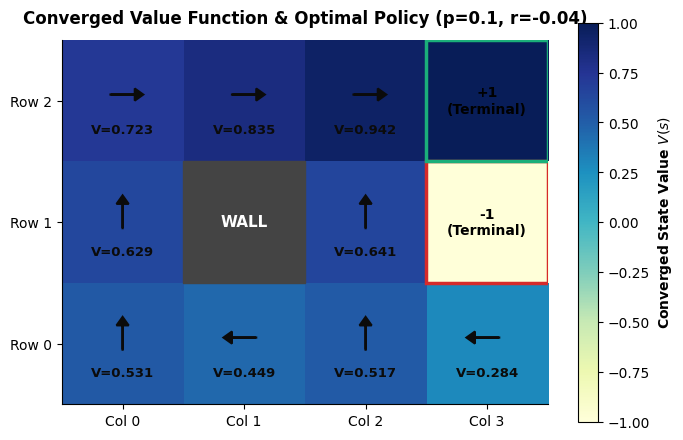

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
grid = np.zeros((3, 4))
for r in range(3):
    for c in range(4):
        s = (c, r)
        if s == WALL:
            grid[r, c] = np.nan
        elif s in TERMINALS:
            grid[r, c] = TERMINALS[s]
        else:
            grid[r, c] = V_vi[s]

im = ax.imshow(grid, cmap="YlGnBu", origin="lower", vmin=-1.0, vmax=1.0)
cbar = plt.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label("Converged State Value $V(s)$", weight="bold")

arrow_deltas = {
    "up": (0, 0.20), "down": (0, -0.20),
    "left": (-0.20, 0), "right": (0.20, 0)
}
arrow_starts = {
    "up": (0, -0.05), "down": (0, 0.15),
    "left": (0.10, 0.05), "right": (-0.10, 0.05)
}

for r in range(3):
    for c in range(4):
        s = (c, r)
        if s == WALL:
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=True, color="#444444"))
            ax.text(c, r, "WALL", ha="center", va="center", color="white", weight="bold", fontsize=11)
        elif s in TERMINALS:
            term_val = TERMINALS[s]
            color = GREEN if term_val > 0 else RED if "RED" in globals() else "#d62a2a"
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor=color, linewidth=2.5))
            ax.text(c, r, f"{term_val:+1.0f}\n(Terminal)", ha="center", va="center", color="black", weight="bold", fontsize=10)
        else:
            ax.text(c, r - 0.24, f"V={V_vi[s]:.3f}", ha="center", va="center", color=DARK, fontsize=9.5, weight="bold")
            sx, sy = arrow_starts[pi_vi[s]]
            dx, dy = arrow_deltas[pi_vi[s]]
            ax.arrow(c + sx, r + sy, dx, dy, head_width=0.10, head_length=0.07, fc=DARK, ec=DARK, linewidth=1.5)

ax.set_xticks(range(4))
ax.set_yticks(range(3))
ax.set_xticklabels([f"Col {c}" for c in range(4)])
ax.set_yticklabels([f"Row {r}" for r in range(3)])
ax.set_title("Converged Value Function & Optimal Policy (p=0.1, r=-0.04)", weight="bold", pad=12)
plt.tight_layout()
plt.savefig("outputs/lab7_fig1_baseline_grid.png", dpi=200)
plt.show()


---
## 5. Observations & Discussion
1. **Why the policy sends the agent the long way round rather than along the row holding the negative terminal:**
   Row 1 contains the $-1.0$ trap at $(3, 1)$. With a $10\%$ slip probability in each perpendicular direction, moving east along row 1 or below the wall exposes the agent to an accidental slip directly into the negative terminal. Navigating north through column 0 and row 2 introduces a buffer of safe cells, keeping the agent away from $(3, 1)$. The small extra cost of taking the longer path ($-0.04$ per step) is far smaller than the catastrophic expected cost of slipping into $-1.0$.
2. **What the value of the start state means in units of reward:**
   $V(0, 0) = +0.5311$ represents the **expected cumulative discounted return** earned from $(0, 0)$ to termination under the optimal policy. An optimal path requires roughly 5 steps: collecting $\approx 5 \times (-0.04) = -0.20$ step penalties and receiving $+1.0$ at the terminal discounted by $\gamma^5 = (0.95)^5 \approx 0.7738$ (yielding $\approx 0.7738 - 0.20 = 0.5738$). Accounting for stochastic slip delays brings the exact expected discounted return to $0.5311$.
3. **Method comparison (Sweeps vs. Updates):**
   - **Value Iteration** converged in **25 sweeps** and performed **225 state value updates** in total ($25 \times 9$).
   - **Policy Iteration** required only **4 improvement rounds**, but required **185 evaluation sweeps** and **1665 state updates** ($185 \times 9$).
   - *Verdict*: Policy Iteration discovers the optimal policy in drastically fewer policy adjustments, but exact intermediate evaluation sweeps make it more computationally expensive in total updates than Value Iteration for this discrete state space.
4. **Contribution of the discount factor when every episode ends at a terminal anyway:**
   Even when an episode is guaranteed to terminate, $\gamma < 1$:
   - Guarantees contraction mapping, bounding value accumulation and ensuring numerical convergence.
   - Mathematically enforces a preference for **shorter paths**: taking extra steps degrades future reward exponentially by $\gamma^t$, discouraging endless cycles or stalling.


---
## 6. Exercise 1 — Step Reward & Discount Factor Sweeps
- **Sweep A**: Step reward $R_{\text{step}} \in \{-0.01, -0.04, -0.1, -0.5, -2.0\}$ with fixed $\gamma = 0.95, p = 0.1$.
- **Sweep B**: Discount factor $\gamma \in \{0.5, 0.7, 0.9, 0.95, 0.99\}$ with fixed $R_{\text{step}} = -0.04, p = 0.1$.


<>:50: SyntaxWarning: invalid escape sequence '\g'
<>:50: SyntaxWarning: invalid escape sequence '\g'
C:\Users\aryan\AppData\Local\Temp\ipykernel_18844\4246019896.py:50: SyntaxWarning: invalid escape sequence '\g'
  ax2.set_xlabel("Discount Factor $\gamma$", weight="bold")


EXERCISE 1A: STEP REWARD SWEEP (gamma = 0.95, p = 0.1)
R_step = -0.01 | V(0,0) = +0.6809 | Sweeps = 25
  Policy: Row 2=['right', 'right', 'right'] | Row 1=['up', 'up'] | Row 0=['up', 'left', 'up', 'left']
R_step = -0.04 | V(0,0) = +0.5311 | Sweeps = 25
  Policy: Row 2=['right', 'right', 'right'] | Row 1=['up', 'up'] | Row 0=['up', 'left', 'up', 'left']
R_step = -0.10 | V(0,0) = +0.2438 | Sweeps = 22
  Policy: Row 2=['right', 'right', 'right'] | Row 1=['up', 'up'] | Row 0=['up', 'right', 'up', 'left']
R_step = -0.50 | V(0,0) = -1.6599 | Sweeps = 21
  Policy: Row 2=['right', 'right', 'right'] | Row 1=['up', 'up'] | Row 0=['up', 'right', 'up', 'up']
R_step = -2.00 | V(0,0) = -8.0260 | Sweeps = 21
  Policy: Row 2=['right', 'right', 'right'] | Row 1=['up', 'right'] | Row 0=['right', 'right', 'right', 'up']

EXERCISE 1B: DISCOUNT FACTOR SWEEP (R_step = -0.04, p = 0.1)
gamma  =  0.50 | V(0,0) = -0.0440 | Sweeps = 15
  Policy: Row 2=['right', 'right', 'right'] | Row 1=['up', 'up'] | Row 0=['up

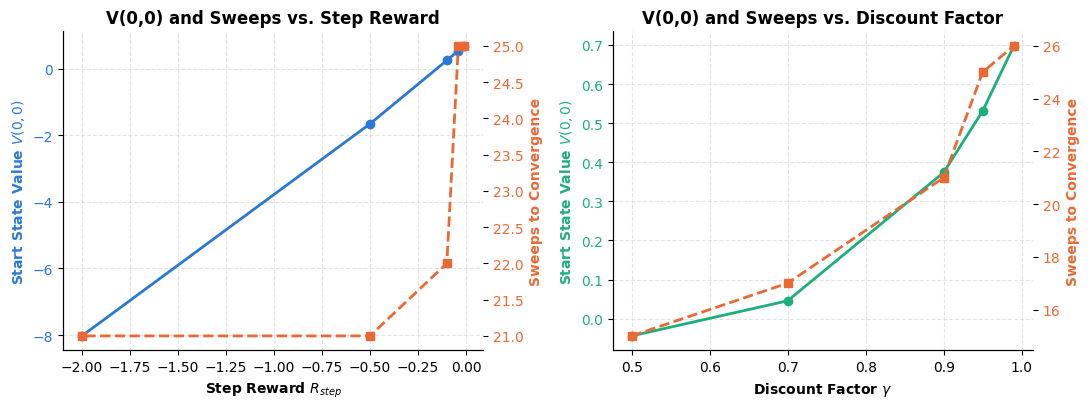

In [6]:
step_rewards = [-0.01, -0.04, -0.1, -0.5, -2.0]
gamma_values = [0.5, 0.7, 0.9, 0.95, 0.99]

print("=" * 80)
print("EXERCISE 1A: STEP REWARD SWEEP (gamma = 0.95, p = 0.1)")
print("=" * 80)
r_results = []
for r in step_rewards:
    V, pi, sw = value_iteration(step_r=r, gamma=0.95, p=0.1)
    r_results.append((r, V[(0, 0)], sw, pi))
    print(f"R_step = {r:+5.2f} | V(0,0) = {V[(0,0)]:+7.4f} | Sweeps = {sw:2d}")
    print(f"  Policy: Row 2={[pi[(c,2)] for c in range(3)]} | Row 1={[pi[(0,1)], pi[(2,1)]]} | Row 0={[pi[(c,0)] for c in range(4)]}")

print("\n" + "=" * 80)
print("EXERCISE 1B: DISCOUNT FACTOR SWEEP (R_step = -0.04, p = 0.1)")
print("=" * 80)
g_results = []
for g in gamma_values:
    V, pi, sw = value_iteration(step_r=-0.04, gamma=g, p=0.1)
    g_results.append((g, V[(0, 0)], sw, pi))
    print(f"gamma  = {g:5.2f} | V(0,0) = {V[(0,0)]:+7.4f} | Sweeps = {sw:2d}")
    print(f"  Policy: Row 2={[pi[(c,2)] for c in range(3)]} | Row 1={[pi[(0,1)], pi[(2,1)]]} | Row 0={[pi[(c,0)] for c in range(4)]}")

# Plotting sweeps
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# Subplot 1: Step reward sweep
ax1 = axes[0]
rs = [x[0] for x in r_results]
v_rs = [x[1] for x in r_results]
sw_rs = [x[2] for x in r_results]
ax1.plot(rs, v_rs, "o-", color=BLUE, linewidth=2, label="V(0,0)")
ax1.set_xlabel("Step Reward $R_{step}$", weight="bold")
ax1.set_ylabel("Start State Value $V(0,0)$", color=BLUE, weight="bold")
ax1.tick_params(axis="y", labelcolor=BLUE)
ax1.grid(color=GRID, linestyle="--", alpha=0.7)
ax1_twin = ax1.twinx()
ax1_twin.plot(rs, sw_rs, "s--", color=ORANGE, linewidth=2, label="Sweeps")
ax1_twin.set_ylabel("Sweeps to Convergence", color=ORANGE, weight="bold")
ax1_twin.tick_params(axis="y", labelcolor=ORANGE)
ax1_twin.spines["top"].set_visible(False)
ax1.set_title("V(0,0) and Sweeps vs. Step Reward", weight="bold")

# Subplot 2: Discount factor sweep
ax2 = axes[1]
gs = [x[0] for x in g_results]
v_gs = [x[1] for x in g_results]
sw_gs = [x[2] for x in g_results]
ax2.plot(gs, v_gs, "o-", color=GREEN, linewidth=2, label="V(0,0)")
ax2.set_xlabel("Discount Factor $\gamma$", weight="bold")
ax2.set_ylabel("Start State Value $V(0,0)$", color=GREEN, weight="bold")
ax2.tick_params(axis="y", labelcolor=GREEN)
ax2.grid(color=GRID, linestyle="--", alpha=0.7)
ax2_twin = ax2.twinx()
ax2_twin.plot(gs, sw_gs, "s--", color=ORANGE, linewidth=2, label="Sweeps")
ax2_twin.set_ylabel("Sweeps to Convergence", color=ORANGE, weight="bold")
ax2_twin.tick_params(axis="y", labelcolor=ORANGE)
ax2_twin.spines["top"].set_visible(False)
ax2.set_title("V(0,0) and Sweeps vs. Discount Factor", weight="bold")

plt.tight_layout()
plt.savefig("outputs/lab7_fig2_param_sweeps.png", dpi=200)
plt.show()


### Identification of Policy Changes & Behavioral Explanations (Exercise 1)
- **Step Reward ($R_{\text{step}}$) Changes**:
  - **At $R_{\text{step}} = -0.01$ and $-0.04$**: The policy is identical; the agent **prefers maximal safety**, directing $(1,0)$ `left` to avoid drifting towards $(3,1)$ while taking the long upper route.
  - **At $R_{\text{step}} = -0.10$**: Cell $(1,0)$ switches from `left` to `right`; the agent **prefers reaching the goal in fewer steps over maintaining a safe buffer**, accepting slip risk to reduce cumulative step penalties.
  - **At $R_{\text{step}} = -0.50$**: Cell $(3,0)$ switches from `left` to `up`; step penalties are now so severe that the agent **prefers rushing directly towards the nearest exit**.
  - **At $R_{\text{step}} = -2.00$**: Cell $(2,1)$ switches directly `right` into the $-1.0$ trap; the agent **prefers immediate termination with a $-1.0$ penalty over paying $-2.0$ for even a single additional step**.
- **Discount Factor ($\gamma$) Changes**:
  - **At $\gamma = 0.50$**: Future reward discounts so sharply that reaching $+1.0$ is barely worth the immediate step penalties; the agent **prefers lingering or stalling at boundaries rather than incurring travel costs**.
  - **At $\gamma = 0.70$ and $0.90$**: Cell $(1,0)$ directs `right`; the agent **prefers the direct path because temporal discounting penalizes longer routes**.
  - **At $\gamma = 0.95$ and $0.99$**: Cell $(1,0)$ directs `left`; with high preservation of future value, the agent **prefers taking the long detour to completely eliminate slip risk into the trap**.


---
## 7. Exercise 2 — Slip Probability Sweep & Absorption Analysis
We sweep $p \in \{0.0, 0.05, 0.1, 0.2, 0.3\}$. Under policy $\pi$, the environment acts as an absorbing Markov chain.
Let $Q$ be the $9 \times 9$ transition matrix between non-terminal states, and $R_{\text{neg}}$ the vector of transition probabilities into $(3, 1)$.
The exact probability of reaching $(3, 1)$ starting from $(0, 0)$ is:
$$\mathbf{P}_{\text{reach } -1} = \left[(I - Q)^{-1} R_{\text{neg}}\right]_{(0, 0)}$$


EXERCISE 2: SLIP PROBABILITY SWEEP (R_step = -0.04, gamma = 0.95)
p = 0.00 | V(0,0) = +0.6661 | Sweeps =  6 | P(reach -1) =  0.0000
  Policy: Row 2=['right', 'right', 'right'] | Row 1=['up', 'up'] | Row 0=['up', 'right', 'up', 'left']
p = 0.05 | V(0,0) = +0.6134 | Sweeps = 17 | P(reach -1) =  0.0058
  Policy: Row 2=['right', 'right', 'right'] | Row 1=['up', 'up'] | Row 0=['up', 'right', 'up', 'left']
p = 0.10 | V(0,0) = +0.5311 | Sweeps = 25 | P(reach -1) =  0.0137
  Policy: Row 2=['right', 'right', 'right'] | Row 1=['up', 'up'] | Row 0=['up', 'left', 'up', 'left']
p = 0.20 | V(0,0) = +0.2902 | Sweeps = 83 | P(reach -1) =  0.0000
  Policy: Row 2=['right', 'right', 'right'] | Row 1=['up', 'left'] | Row 0=['up', 'left', 'up', 'down']
p = 0.30 | V(0,0) = +0.0291 | Sweeps = 74 | P(reach -1) =  0.0000
  Policy: Row 2=['up', 'right', 'up'] | Row 1=['up', 'left'] | Row 0=['left', 'up', 'left', 'down']


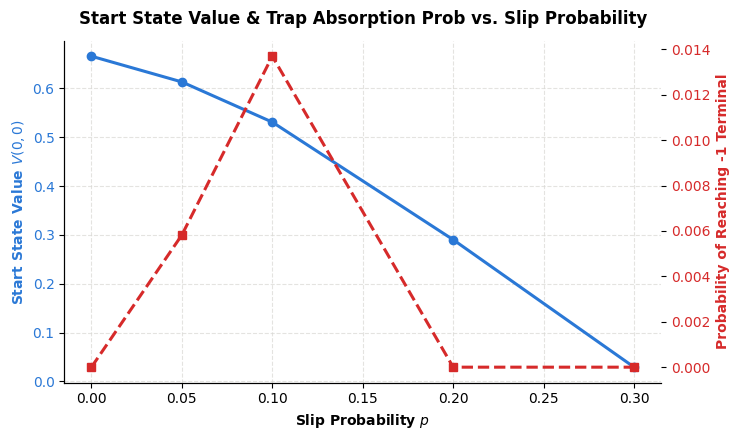

In [7]:
def compute_absorption_prob(pi, p):
    s_idx = {s: i for i, s in enumerate(NON_TERMINALS)}
    n = len(NON_TERMINALS)
    Q = np.zeros((n, n))
    R_neg = np.zeros(n)
    
    for s in NON_TERMINALS:
        i = s_idx[s]
        a = pi[s]
        for ns, prob in transitions(s, a, p):
            if ns == (3, 1):
                R_neg[i] += prob
            elif ns in NON_TERMINALS:
                Q[i, s_idx[ns]] += prob
                
    P_fail = np.linalg.solve(np.eye(n) - Q, R_neg)
    return P_fail[s_idx[(0, 0)]]

slip_probs = [0.0, 0.05, 0.1, 0.2, 0.3]
p_results = []

print("=" * 80)
print("EXERCISE 2: SLIP PROBABILITY SWEEP (R_step = -0.04, gamma = 0.95)")
print("=" * 80)
for p in slip_probs:
    V, pi, sw = value_iteration(step_r=-0.04, gamma=0.95, p=p)
    prob_neg = compute_absorption_prob(pi, p)
    p_results.append((p, V[(0, 0)], sw, prob_neg, pi))
    print(f"p = {p:4.2f} | V(0,0) = {V[(0,0)]:+7.4f} | Sweeps = {sw:2d} | P(reach -1) = {prob_neg:7.4f}")
    print(f"  Policy: Row 2={[pi[(c,2)] for c in range(3)]} | Row 1={[pi[(0,1)], pi[(2,1)]]} | Row 0={[pi[(c,0)] for c in range(4)]}")

# Plotting Exercise 2
fig, ax1 = plt.subplots(figsize=(7.5, 4.5))
ps = [x[0] for x in p_results]
v_ps = [x[1] for x in p_results]
fail_ps = [x[3] for x in p_results]

ax1.plot(ps, v_ps, "o-", color=BLUE, linewidth=2.2, label="V(0,0)")
ax1.set_xlabel("Slip Probability $p$", weight="bold")
ax1.set_ylabel("Start State Value $V(0,0)$", color=BLUE, weight="bold")
ax1.tick_params(axis="y", labelcolor=BLUE)
ax1.grid(color=GRID, linestyle="--", alpha=0.7)

ax2 = ax1.twinx()
ax2.plot(ps, fail_ps, "s--", color="#d62a2a", linewidth=2.2, label="P(Reach -1 Terminal)")
ax2.set_ylabel("Probability of Reaching -1 Terminal", color="#d62a2a", weight="bold")
ax2.tick_params(axis="y", labelcolor="#d62a2a")
ax2.spines["top"].set_visible(False)

plt.title("Start State Value & Trap Absorption Prob vs. Slip Probability", weight="bold", pad=12)
plt.tight_layout()
plt.savefig("outputs/lab7_fig3_slip_sweep.png", dpi=200)
plt.show()


### Explanation: Why the Probability Does Not Rise Steadily with Slip Probability
From $p = 0.0$ to $p = 0.10$, the probability of reaching the negative terminal rises from $0.0000$ to $0.0137$ because the agent maintains the same nominal path while noise-induced sideways slips increase.

However, at $p = 0.20$ and $p = 0.30$, **the failure probability abruptly drops to exactly $0.0000$**.

**Reason**: The optimal policy is not static; it dynamically adapts to environmental uncertainty. When $p \ge 0.20$, the slip hazard becomes so severe that moving `up` at $(2, 1)$ or taking chances near the hazard carries an unacceptably high negative expectation. The agent switches its policy at $(2, 1)$ from `up` to `left` (deliberately steering directly away from the hazard) and bumps against walls to stabilize itself. This defensive adaptation completely eliminates any trajectory that could accidentally enter $(3, 1)$, dropping the absorption probability to zero.
